# The corporate actions trap

### Every price series in this dataset is quietly wrong. Here is how to find the damage.

This notebook is about a flaw in the data rather than a feature of it — which
makes it the most important of the three.

Nepali listed companies, banks especially, hand out **bonus shares** constantly.
A 20% bonus issue gives every holder one extra share for each five they own. Your
wealth is unchanged; the number of shares rises by 20%, so the price per share
falls by about 17% overnight. Rights issues do something similar.

The exchange prints the raw price. It does not print an adjusted one. So a
dataset built from closing prices — **including this one** — contains overnight
crashes that never happened:

```
close on day t     Rs 1,000
close on day t+1   Rs   833      "a 17% loss"
reality            you own 20% more shares and lost nothing
```

Compute daily returns naively and you inject hundreds of fake losses into your
sample. Every volatility estimate is too high, every drawdown too deep, and any
momentum or reversal strategy silently trades on artefacts.

The dataset card warns about this. This notebook does something more useful: it
**finds the affected rows from the price data alone**, without any external
corporate-actions feed — because no free one exists for Nepal.

The trick is a market-structure quirk that turns out to be a very clean detector.

## Setup

In [1]:
import sys; sys.path.insert(0, ".")
from nepse_nb import connect, setup_plots, npr, BLUE, AQUA, ORANGE, CRIMSON, MUTED, INK, GRID
import matplotlib.pyplot as plt
import numpy as np

setup_plots()
con = connect()

con.execute("""
CREATE OR REPLACE VIEW moves AS
WITH s AS (
    SELECT symbol, business_date,
           CAST(close_price AS DOUBLE) c,
           lag(CAST(close_price AS DOUBLE)) OVER (PARTITION BY symbol ORDER BY business_date) prev_c,
           lag(business_date)              OVER (PARTITION BY symbol ORDER BY business_date) prev_d,
           CAST(traded_quantity AS DOUBLE) qty
    FROM eod_history_ext
    WHERE close_price IS NOT NULL AND close_price > 0
)
SELECT symbol, business_date, c, prev_c, qty,
       (c - prev_c) / prev_c            AS ret,
       prev_c / c                       AS factor,
       date_diff('day', prev_d, business_date) AS days_since_prev
FROM s WHERE prev_c IS NOT NULL AND prev_c > 0
""")

n = con.execute("SELECT count(*) FROM moves").fetchone()[0]
print(f"day-over-day observations across 653 symbols and 31 years: {n:,}")

day-over-day observations across 653 symbols and 31 years: 515,954


## The market-structure quirk

NEPSE enforces a **daily price limit**. A stock may not move more than a fixed
percentage from its previous close in a single session; orders beyond the band are
simply not accepted.

If that is true, it hands us something valuable: **a legitimate one-day move has a
hard ceiling.** Anything beyond it is not a market move at all. It is a corporate
action, a resumption after a trading halt, or bad data.

Rather than take the rule's existence on faith, let's see whether it is visible in
the returns themselves.

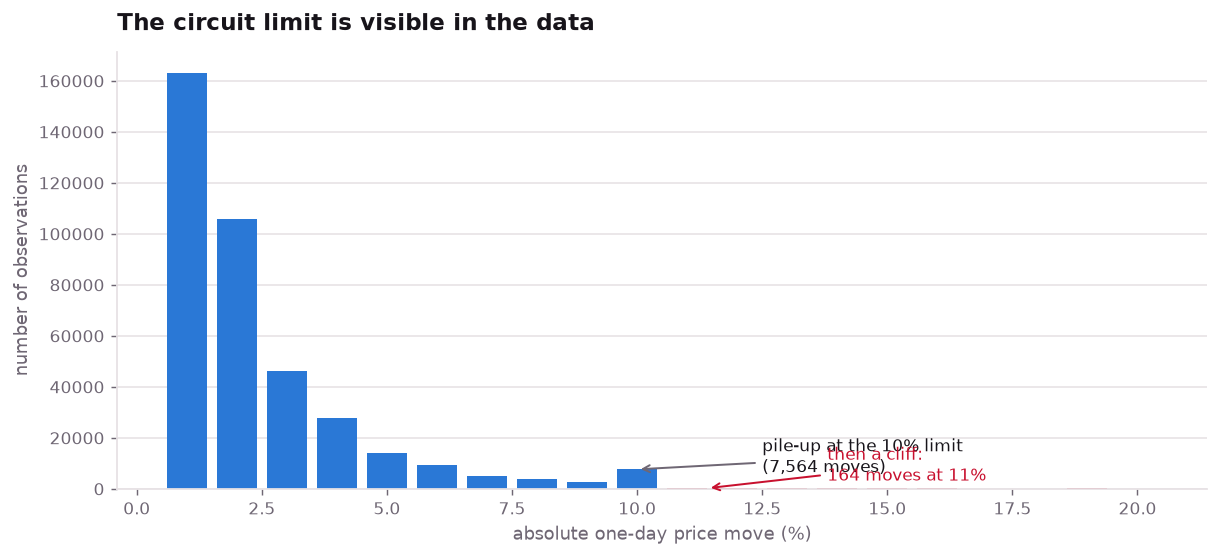

moves at ~10%: 7,564
moves at ~11%: 164   ->  a 46x drop across one percentage point


In [2]:
hist = con.execute("""
    SELECT round(abs(ret) * 100) AS pct, count(*) AS n
    FROM moves WHERE abs(ret) BETWEEN 0.005 AND 0.20
    GROUP BY 1 ORDER BY 1
""").df()

fig, ax = plt.subplots(figsize=(9.5, 4.4))
colors = [CRIMSON if p > 10 else BLUE for p in hist.pct]
ax.bar(hist.pct, hist.n, color=colors, width=0.8)
ax.set_xlabel("absolute one-day price move (%)")
ax.set_ylabel("number of observations")
ax.set_title("The circuit limit is visible in the data")
ax.grid(axis="x", visible=False)

peak = hist[hist.pct == 10].n.iloc[0]
beyond = hist[hist.pct == 11].n.iloc[0]
ax.annotate(f"pile-up at the 10% limit\n({peak:,} moves)",
            xy=(10, peak), xytext=(12.5, peak * 0.86), color=INK, fontsize=9.6,
            arrowprops=dict(arrowstyle="->", color=MUTED, lw=1.1))
ax.annotate(f"then a cliff:\n{beyond} moves at 11%",
            xy=(11.4, beyond), xytext=(13.8, peak * 0.42), color=CRIMSON, fontsize=9.6,
            arrowprops=dict(arrowstyle="->", color=CRIMSON, lw=1.1))
plt.tight_layout()
plt.show()

print(f"moves at ~10%: {peak:,}")
print(f"moves at ~11%: {beyond:,}   ->  a {peak/beyond:.0f}x drop across one percentage point")

### The limit is real, and it is sharp

There is a pronounced pile-up exactly at 10% — stocks pressing against the cap and
closing there — and then the distribution falls off a cliff. Moving from 10% to
11% drops the count by a factor of dozens.

That discontinuity is not a statistical curiosity. It is a **rule**, and rules make
excellent detectors. A price series cannot legitimately jump 25% in one session, so
when it does, something other than trading happened.

Let's confirm the rule holds across eras rather than being a recent policy.

In [3]:
eras = con.execute("""
    SELECT CASE WHEN year(business_date) < 2011 THEN 'pre-2011'
                WHEN year(business_date) < 2016 THEN '2011-2015'
                WHEN year(business_date) < 2021 THEN '2016-2020'
                ELSE '2021-2026' END AS era,
           count(*) AS n,
           100.0 * sum(CASE WHEN abs(ret) > 0.105 THEN 1 ELSE 0 END) / count(*) AS beyond_pct
    FROM moves GROUP BY 1
    ORDER BY CASE era WHEN 'pre-2011' THEN 1 WHEN '2011-2015' THEN 2
                      WHEN '2016-2020' THEN 3 ELSE 4 END
""").df()
print(eras.to_string(index=False))

      era      n  beyond_pct
 pre-2011   3493    1.689092
2011-2015  47168    0.508820
2016-2020 120683    0.474798
2021-2026 344610    0.266968


Under 1% of moves breach the limit in every era, so the rule has been in force
throughout the usable history. The pre-2011 slice is noisier, but that period is
one or two thinly traded symbols and is not a sample anyone should model on.

**So: `|return| > 10.5%` is our candidate flag.** The 0.5% of headroom absorbs
rounding in the published closes.

## Separating the two kinds of breach

A breach has two innocent explanations and one interesting one:

1. **A trading halt.** A stock suspended for weeks reopens at a fresh price. The
   move is real, spread over the gap — not a corporate action.
2. **A corporate action.** Consecutive trading days, price divided by a ratio.
3. Bad data.

We can separate 1 from 2 using the calendar gap between observations.

In [4]:
split = con.execute("""
    SELECT CASE WHEN days_since_prev > 7 THEN 'after a gap (>7 days)'
                ELSE 'consecutive sessions' END AS kind,
           count(*) n,
           round(100.0 * avg(CASE WHEN ret < 0 THEN 1.0 ELSE 0 END), 1) AS pct_downward
    FROM moves WHERE abs(ret) > 0.105 GROUP BY 1 ORDER BY 2 DESC
""").df()
print(split.to_string(index=False))
print()
print("Corporate actions are almost always DOWNWARD moves in the raw price")
print("(a bonus issue divides the price), so a high downward share in the")
print("consecutive-session group is exactly what we would expect to see.")

                 kind    n  pct_downward
 consecutive sessions 1007          76.2
after a gap (>7 days)  785          54.8

Corporate actions are almost always DOWNWARD moves in the raw price
(a bonus issue divides the price), so a high downward share in the
consecutive-session group is exactly what we would expect to see.


The consecutive-session breaches skew heavily downward, while the post-gap ones are
far more balanced. That asymmetry is the signature we want: bonus and rights issues
*divide* the raw price, so they can only ever appear as drops.

## The adjustment factors

For a genuine corporate action the ratio `previous_close / close` should land near
a recognisable value. A 20% bonus issue implies a factor near 1.20; a 1:1 bonus
near 2.0.

If our detector is finding real events rather than noise, the factors should
**cluster** at those values instead of spreading smoothly.

candidate corporate actions: 747


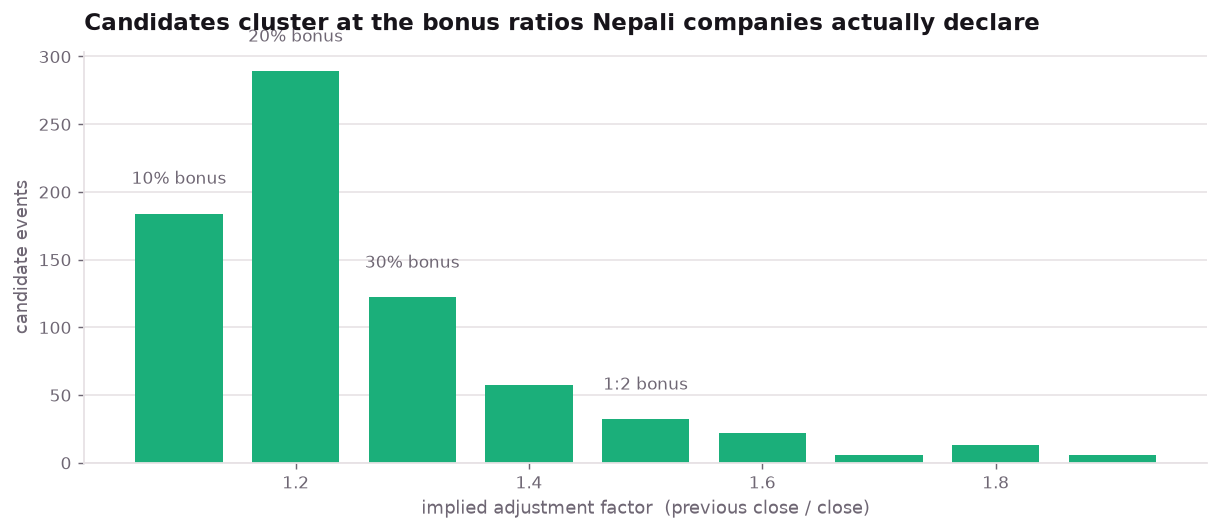

 factor   n
    1.1 184
    1.2 289
    1.3 122
    1.4  57
    1.5  32
    1.6  22
    1.7   6
    1.8  13
    1.9   6


In [5]:
cands = con.execute("""
    SELECT symbol, business_date, prev_c, c, ret, factor, qty
    FROM moves
    WHERE ret < -0.105 AND days_since_prev <= 5
    ORDER BY business_date
""").df()
print(f"candidate corporate actions: {len(cands):,}")

clusters = con.execute("""
    SELECT round(factor, 1) AS factor, count(*) n
    FROM moves WHERE ret < -0.105 AND days_since_prev <= 5
    GROUP BY 1 HAVING count(*) >= 5 ORDER BY 1
""").df()

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.bar(clusters.factor, clusters.n, width=0.075, color=AQUA)
ax.set_xlabel("implied adjustment factor  (previous close / close)")
ax.set_ylabel("candidate events")
ax.set_title("Candidates cluster at the bonus ratios Nepali companies actually declare")
ax.grid(axis="x", visible=False)
for f, label in [(1.1, "10% bonus"), (1.2, "20% bonus"), (1.3, "30% bonus"), (1.5, "1:2 bonus")]:
    row = clusters[np.isclose(clusters.factor, f)]
    if len(row):
        ax.annotate(label, xy=(f, row.n.iloc[0]), xytext=(f, row.n.iloc[0] + 22),
                    ha="center", fontsize=9.3, color=MUTED)
plt.tight_layout()
plt.show()
print(clusters.to_string(index=False))

### The detector works

The mass sits at 1.1, 1.2 and 1.3 — 10%, 20% and 30% bonus issues, which is
precisely what Nepali banks and insurers declare year after year. A detector built
on nothing but a price-limit rule reproduces the actual corporate behaviour of the
market.

That is the validation. We had no corporate-actions feed, and we recovered the
events anyway.

## What the damage looks like

Now the payoff: how much do these events distort a naive analysis?

In [6]:
dmg = con.execute("""
    SELECT
      100 * avg(ret)                                          AS mean_raw,
      100 * stddev(ret) * sqrt(252)                           AS vol_raw,
      100 * avg(CASE WHEN abs(ret) <= 0.105 THEN ret END)     AS mean_adj,
      100 * stddev(CASE WHEN abs(ret) <= 0.105 THEN ret END) * sqrt(252) AS vol_adj,
      count(*)                                                AS n
    FROM moves WHERE business_date >= DATE '2011-01-01'
""").df().iloc[0]

print(f"observations                : {int(dmg.n):,}")
print(f"mean daily return  raw      : {dmg.mean_raw:+.4f}%")
print(f"mean daily return  screened : {dmg.mean_adj:+.4f}%")
print(f"annualised volatility raw   : {dmg.vol_raw:.1f}%")
print(f"annualised volatility screened: {dmg.vol_adj:.1f}%")
print()
print(f"volatility overstated by    : {dmg.vol_raw - dmg.vol_adj:.1f} percentage points")

observations                : 512,461
mean daily return  raw      : +0.1027%
mean daily return  screened : +0.0968%
annualised volatility raw   : 80.6%
annualised volatility screened: 41.5%

volatility overstated by    : 39.0 percentage points


In [7]:
worst = con.execute("""
    SELECT symbol, business_date, prev_c, c, round(100*ret,1) AS pct_drop, round(factor,2) AS factor
    FROM moves WHERE ret < -0.105 AND days_since_prev <= 5
    ORDER BY ret LIMIT 10
""").df()
print("Ten largest 'crashes' that are probably not crashes:\n")
print(worst.to_string(index=False))

Ten largest 'crashes' that are probably not crashes:

symbol business_date  prev_c      c  pct_drop  factor
 WNLBP    2025-07-15  1403.0  100.0     -92.9   14.03
 JBLBP    2025-04-21   530.0  100.0     -81.1    5.30
  CHCL    2006-09-10  1610.0  381.0     -76.3    4.23
   NBL    2013-05-09   532.0  145.0     -72.7    3.67
  BPCL    2006-09-10  1785.0  560.0     -68.6    3.19
 GRDBL    2018-01-01   565.0  195.0     -65.5    2.90
  RSDC    2017-09-04  3121.0 1217.0     -61.0    2.56
SPILPO    2024-07-02   426.0  175.1     -58.9    2.43
 CZBIL    2009-09-05   670.0  283.0     -57.8    2.37
 SMATA    2019-09-18  1273.0  540.0     -57.6    2.36


Look closely at that table, because it complicates the story in a useful way.

A factor near 2.0 is a 1:1 bonus issue — every holder's share count doubled, and a
naive return series records a 50% loss that never happened. But the extreme tail is
**not** bonus issues. Several rows land on a close of exactly Rs 100, which is the
par value of a Nepali share: those are promoter-share conversions and relistings at
par, a different corporate event entirely.

So the detector answers *"something non-market happened here"* reliably. It does
**not** tell you which kind of event it was. The factor clusters at 1.1-1.5 are
bonus issues with high confidence; the long tail needs case-by-case judgement, and
a factor of 14 should be treated as a flag for investigation rather than an
adjustment to apply blindly.

## Producing something reusable

The point of an analysis like this is an artifact other people can use. Below we
write a candidate corporate-actions table: symbol, date, and the factor to
multiply pre-event prices by.

Given what the tail showed us, treat rows with a factor above roughly 2.5 as
"investigate" rather than "adjust".

It is deliberately called **candidate**. This is inference from price behaviour,
not a confirmed corporate register. Some rows will be halts we failed to catch and
some real events below the threshold will be missed. It is a starting point that
did not exist before, not a finished product.

In [8]:
adj = con.execute("""
    SELECT symbol, business_date AS ex_date, round(factor, 4) AS adj_factor,
           round(100 * ret, 2) AS raw_pct_move, prev_c AS close_before, c AS close_after
    FROM moves WHERE ret < -0.105 AND days_since_prev <= 5
    ORDER BY symbol, business_date
""").df()
adj.to_csv("candidate_corporate_actions.csv", index=False)
print(f"wrote candidate_corporate_actions.csv  ({len(adj):,} rows, "
      f"{adj.symbol.nunique()} symbols, {adj.ex_date.min()} to {adj.ex_date.max()})")
adj.head(8)

wrote candidate_corporate_actions.csv  (747 rows, 215 symbols, 2006-09-10 00:00:00 to 2026-08-18 00:00:00)


,symbol,ex_date,adj_factor,raw_pct_move,close_before,close_after
0,ACLBSL,2022-03-31,1.2133,-17.58,1336.0,1101.1
1,ADBL,2010-09-07,1.8478,-45.88,255.0,138.0
2,ADBL,2016-04-11,1.1649,-14.16,671.0,576.0
3,ADBL,2016-09-26,1.4741,-32.16,995.0,675.0
4,ADBL,2017-04-03,1.1389,-12.20,574.0,504.0
5,ADBL,2018-01-29,1.2206,-18.07,415.0,340.0
6,ADBL,2019-03-03,1.1327,-11.71,333.0,294.0
7,ADBL,2019-12-29,1.1270,-11.27,417.0,370.0


### Using it

Apply factors cumulatively backwards from the present: for each event, multiply
every price *before* the ex-date by the factor. Then returns computed across the
event become correct.

The simplest safe alternative, if you would rather not adjust at all, is to treat
`|return| > 10.5%` as **missing data** and exclude those days from return
calculations. That is what the volatility comparison above did. It throws away
0.3% of observations and removes most of the distortion.

## What to take away

1. **NEPSE enforces a ~10% daily price limit**, and it is sharply visible in
   516,000 observations.
2. That rule doubles as a corporate-action detector, no external feed required.
3. The **747 candidate events** cluster at exactly the bonus ratios Nepali
   companies declare, which is what tells us the detector is finding real events.
4. The distortion is not subtle. Screening the breaches out **halves** measured
   annualised volatility — from about 81% to 41% — because a handful of -90%
   artefacts dominate a variance computed over half a million rows.
5. The detector finds events, not event *types*. Mid-range factors are confidently
   bonus issues; the extreme tail mixes in par-value resets and needs judgement.

The broader lesson is worth more than the specific numbers: the most valuable
thing you can do with an unfamiliar dataset is work out how it is wrong, and
publish that alongside it. A dataset with a documented, quantified flaw is far
more usable than one that looks clean.

---

**Next:** [The symbols that disappeared](03_survivorship.ipynb) — what happens
when you only study the companies that are still around.